In [50]:
import scanpy as sc
import pandas as pd
import numpy as np
import sys
import random
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
import warnings

warnings.filterwarnings("ignore")

In [3]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [4]:
sc.set_figure_params(figsize=(5, 5))

read in mapqc results:

In [7]:
results_healthy = mapqc.load(
    "../../../results/HLCA/Thienpont/Thienpont_2018_10Xv2_kl1_sample_as_batch/mapqc_results_healthy_pleimorphic_carc_removed.pkl"
)
results_disease = mapqc.load(
    "../../../results/HLCA/Thienpont/Thienpont_2018_10Xv2_kl1_sample_as_batch/mapqc_results_disease_pleimorphic_carc_removed.pkl"
)

read in embedding with mapped query:

In [63]:
adata_emb = sc.read_h5ad(
    "../../../results/HLCA/Thienpont/Thienpont_2018_10Xv2_kl1_sample_as_batch/combined_embedding_klweight_1.h5ad"
)

shuffle row order emb for plotting:

In [64]:
shuffled_idc = adata_emb.obs.index.tolist()
random.shuffle(shuffled_idc)
adata_emb = adata_emb[shuffled_idc, :].copy()

add mapQC results to embedding with both healthy and diseased:

In [65]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_emb.obs[stat] = np.nan
    healthy_idc = [
        idx for idx in adata_emb.obs.index if idx in results_healthy.adata.obs.index
    ]
    adata_emb.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx for idx in adata_emb.obs.index if idx in results_disease.adata.obs.index
    ]
    adata_emb.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[
        disease_idc, stat
    ]

read in raw reference data in backed mode:

In [14]:
adata_full = sc.read_h5ad(
    "../../../../../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/d10_1101_2022_03_10_483747/HLCA_v1.1_full.h5ad",
    backed="r",
)

In [15]:
adata_emb

AnnData object with n_obs × n_vars = 678519 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

### Visualize mapQC results on controls:

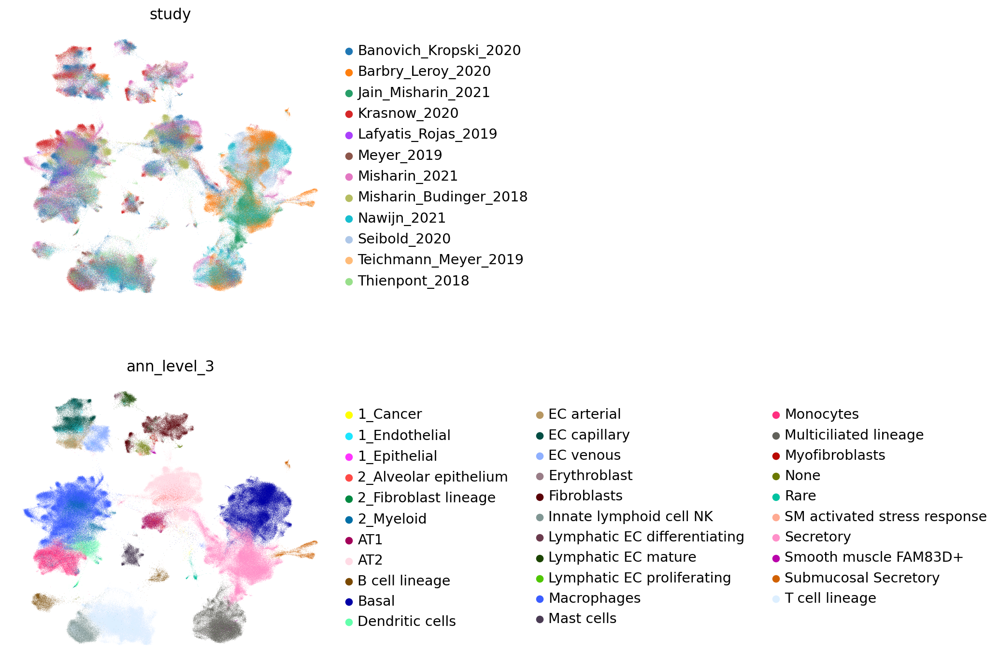

In [16]:
sc.pl.umap(
    results_healthy.adata, color=["study", "ann_level_3"], frameon=False, ncols=1
)

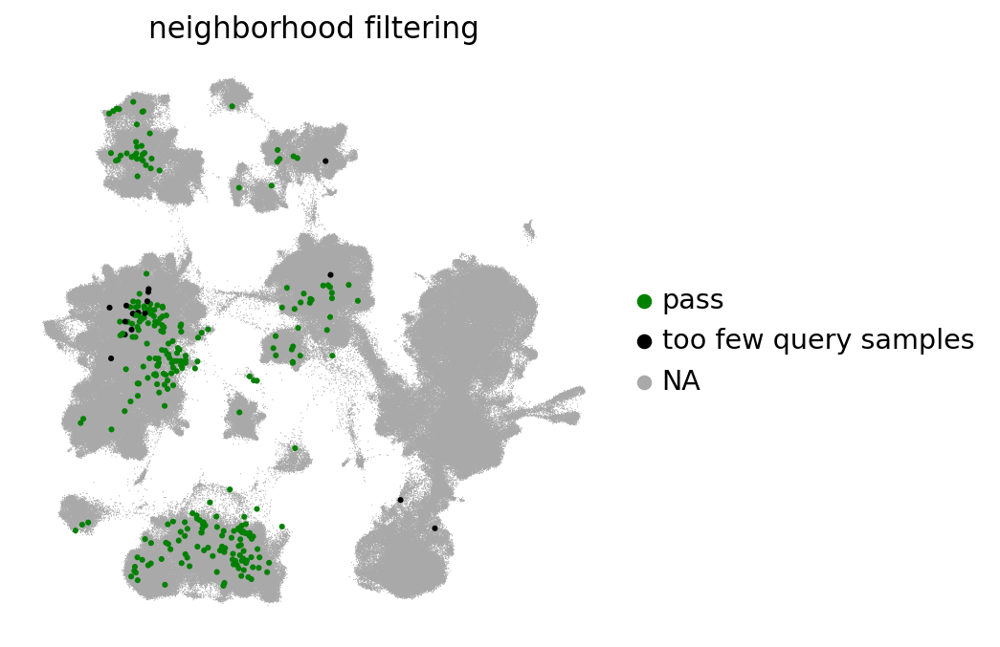

In [17]:
plotting.plot_umap_filtering_info(results_healthy)

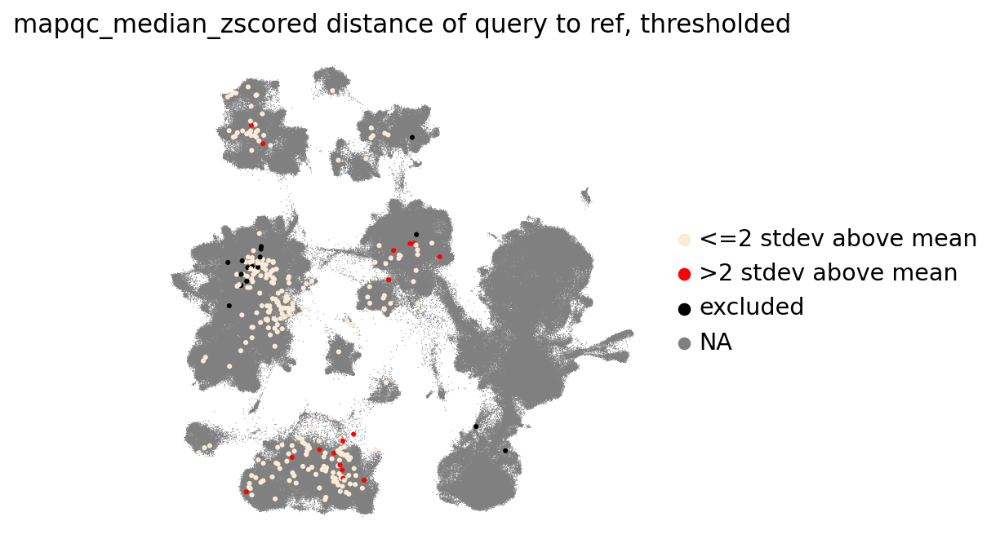

In [18]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="median_zscore>2")

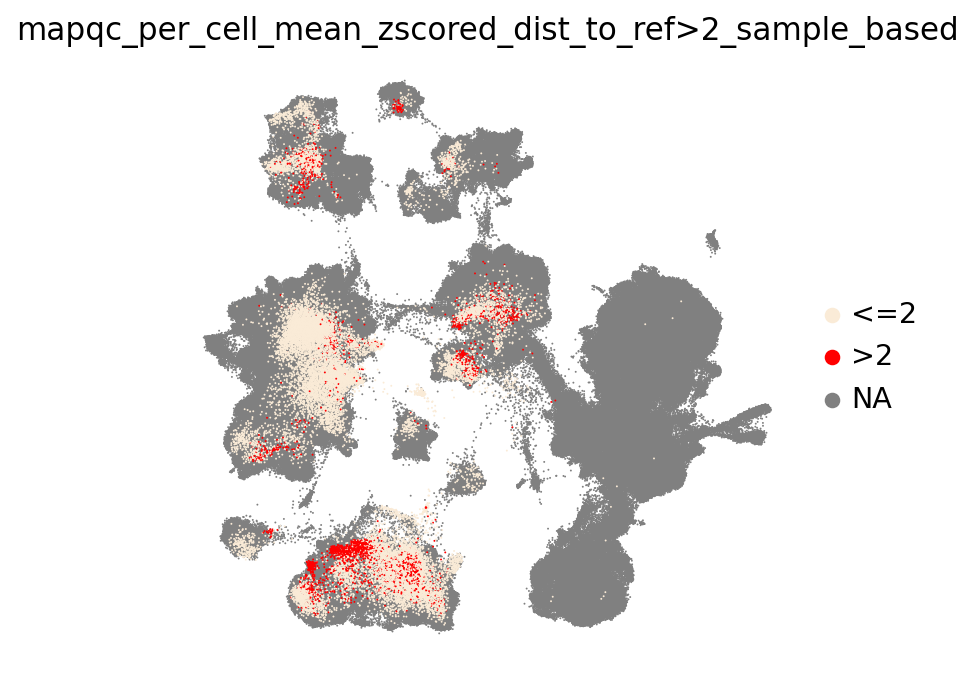

In [19]:
plotting.plot_umap_cell_level_results(results_healthy, size=3)

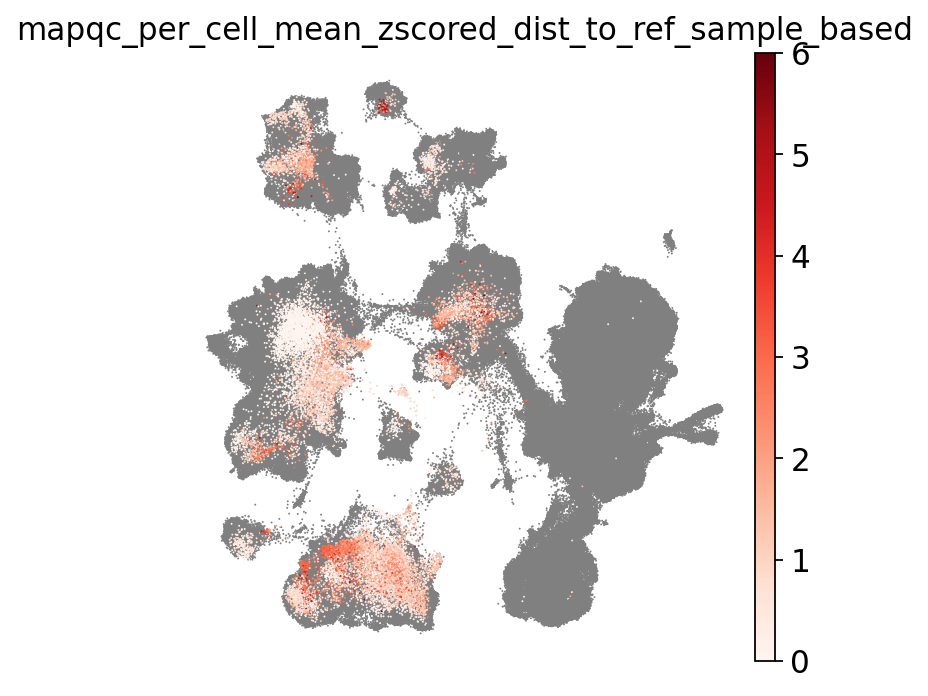

In [20]:
plotting.plot_umap_cell_level_results(
    results_healthy, size=3, color_by="zscore", vmin=0, vmax=6
)

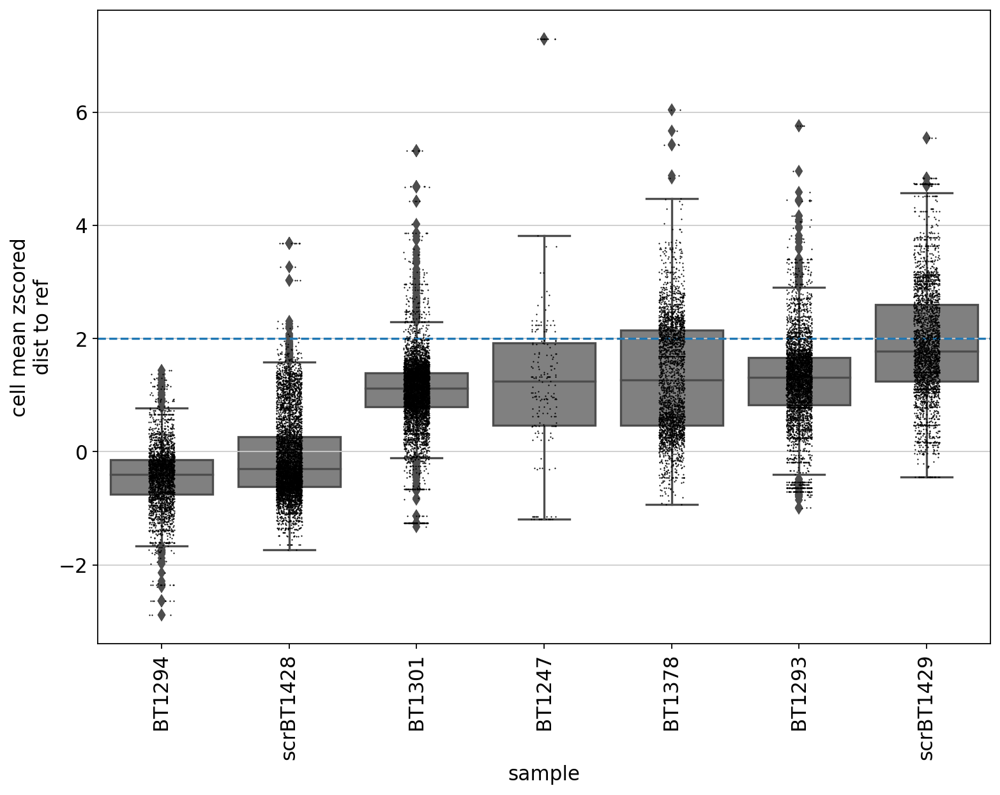

In [21]:
plotting.plot_sample_distances_to_reference_cell_level(results_healthy)

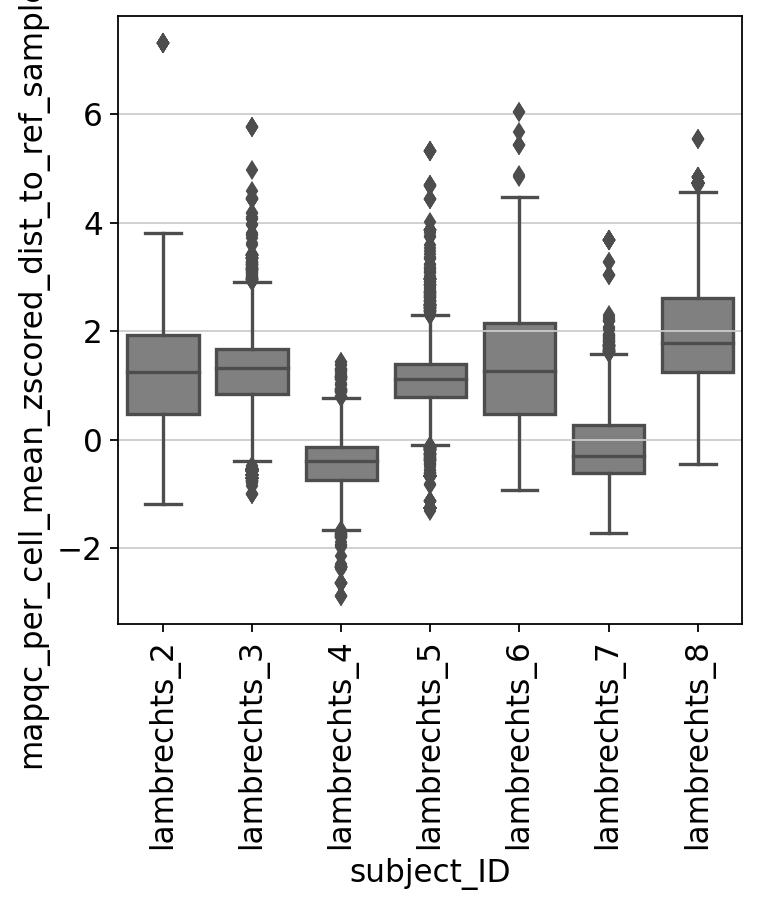

In [54]:
fig, ax = plt.subplots()
sns.boxplot(
    results_healthy.adata.obs,
    x="subject_ID",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    color="grey",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)

In [59]:
results_healthy.adata.obs.groupby("subject_ID").agg(
    {"sample": "unique", "cancer_type": "first"}
)

,sample,cancer_type
subject_ID,,
lambrechts_2,"['BT1247'] Categories (173, object): ['356C_0h...",Squamous Cell Carcinoma
lambrechts_3,"['BT1293'] Categories (173, object): ['356C_0h...",Adenocarcinoma
lambrechts_4,"['BT1294'] Categories (173, object): ['356C_0h...",Adenocarcinoma
lambrechts_5,"['BT1301'] Categories (173, object): ['356C_0h...",Large Cell Carcinoma
lambrechts_6,"['BT1378'] Categories (173, object): ['356C_0h...",Adenocarcinoma
lambrechts_7,"['scrBT1428'] Categories (173, object): ['356C...",Squamous Cell Carcinoma
lambrechts_8,"['scrBT1429'] Categories (173, object): ['356C...",Pleiomorphic Carcinoma


### Visualize results disease:

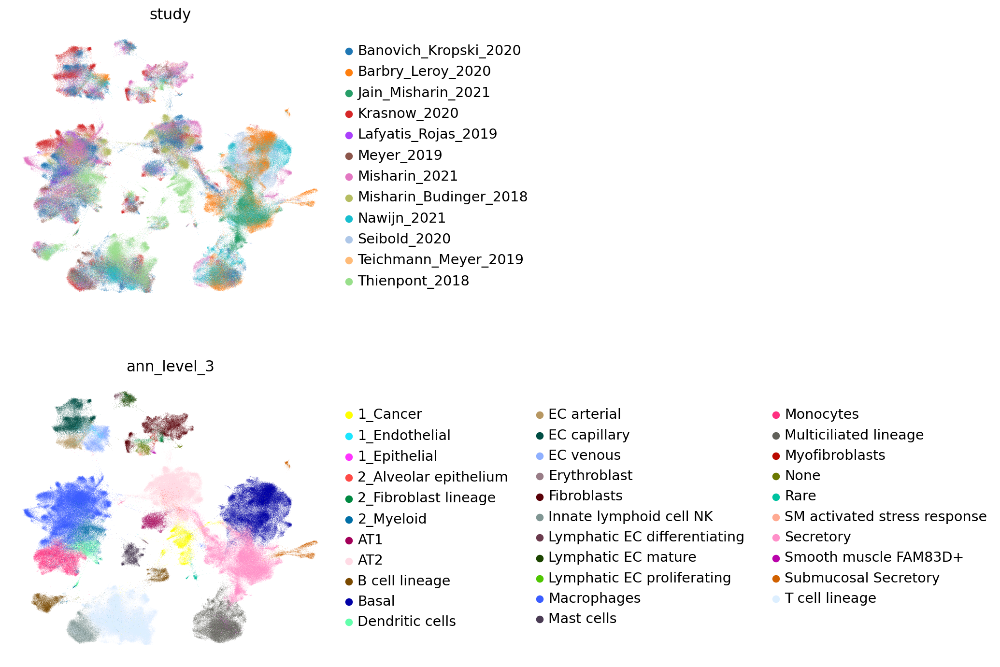

In [22]:
sc.pl.umap(
    results_disease.adata, color=["study", "ann_level_3"], frameon=False, ncols=1
)

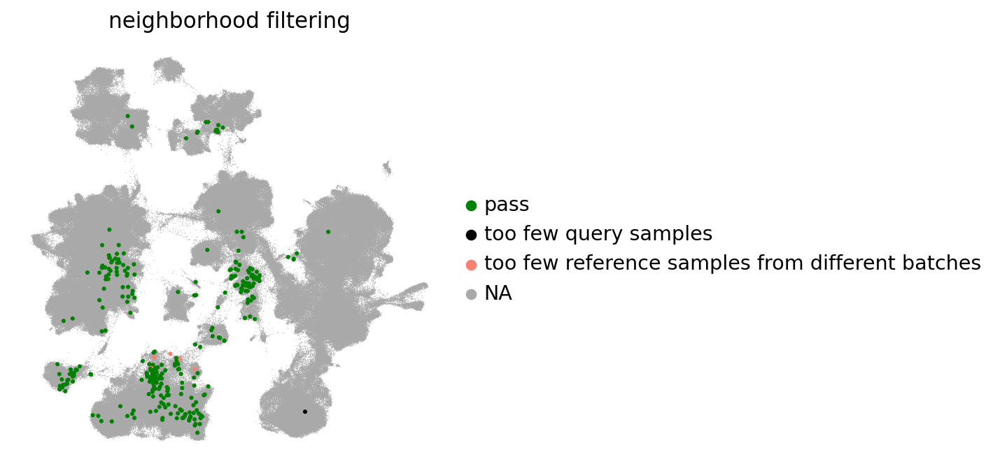

In [23]:
plotting.plot_umap_filtering_info(results_disease)

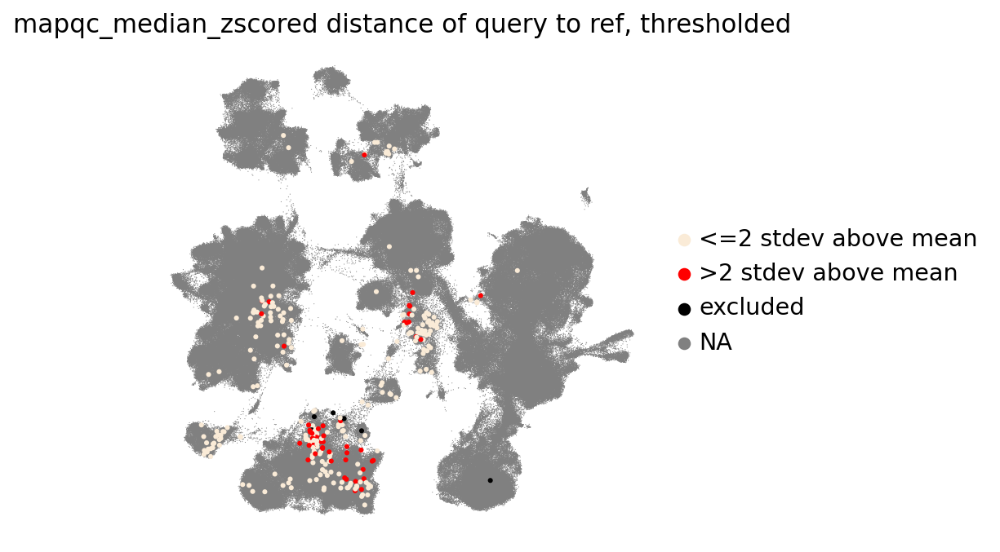

In [24]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="median_zscore>2")

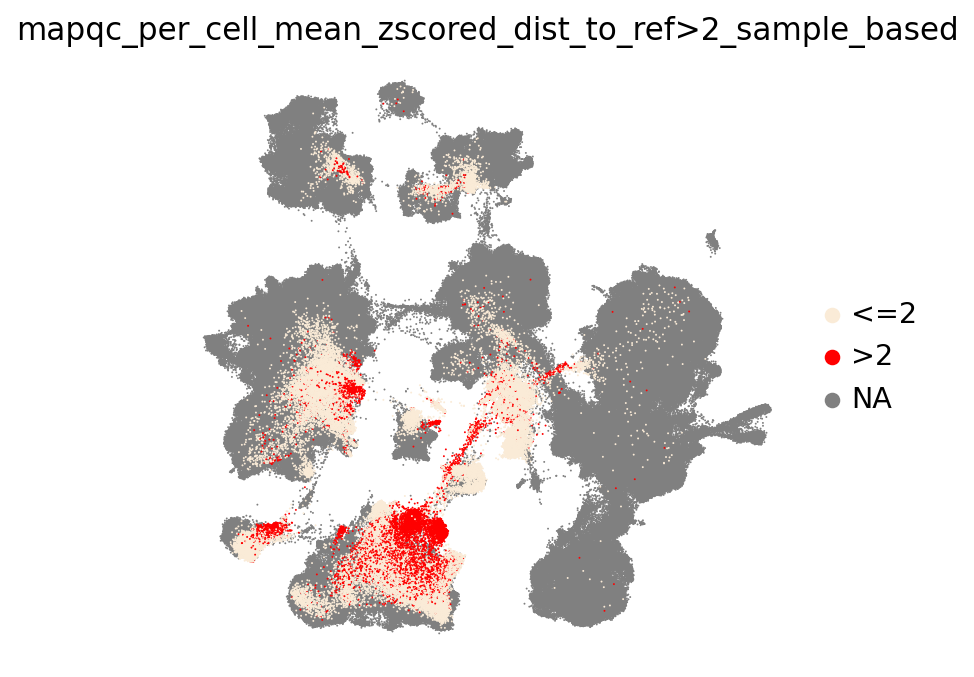

In [25]:
plotting.plot_umap_cell_level_results(results_disease, size=3)

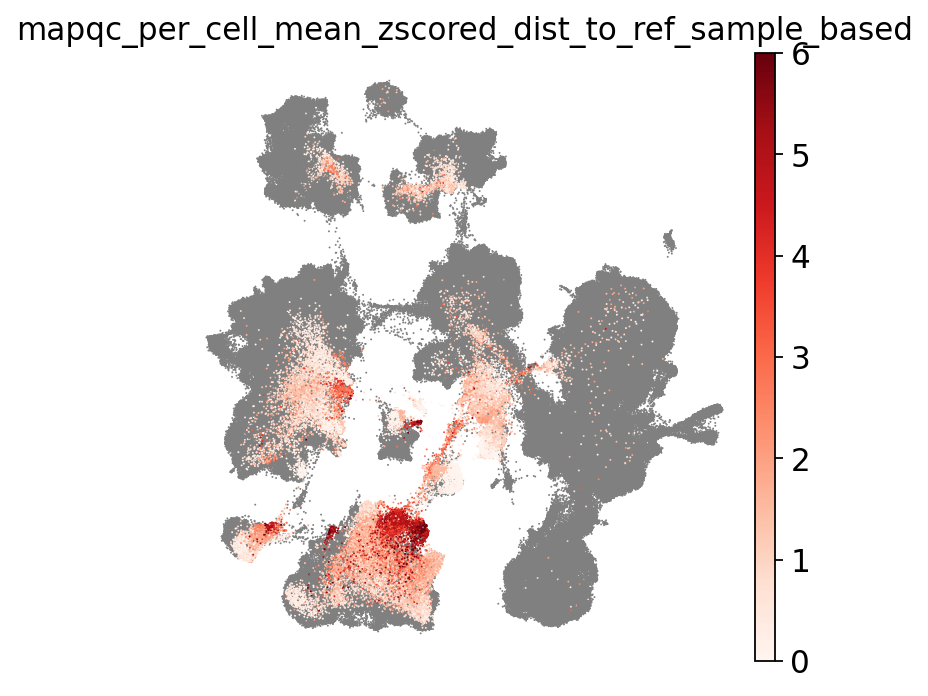

In [26]:
plotting.plot_umap_cell_level_results(
    results_disease, size=3, color_by="zscore", vmin=0, vmax=6
)

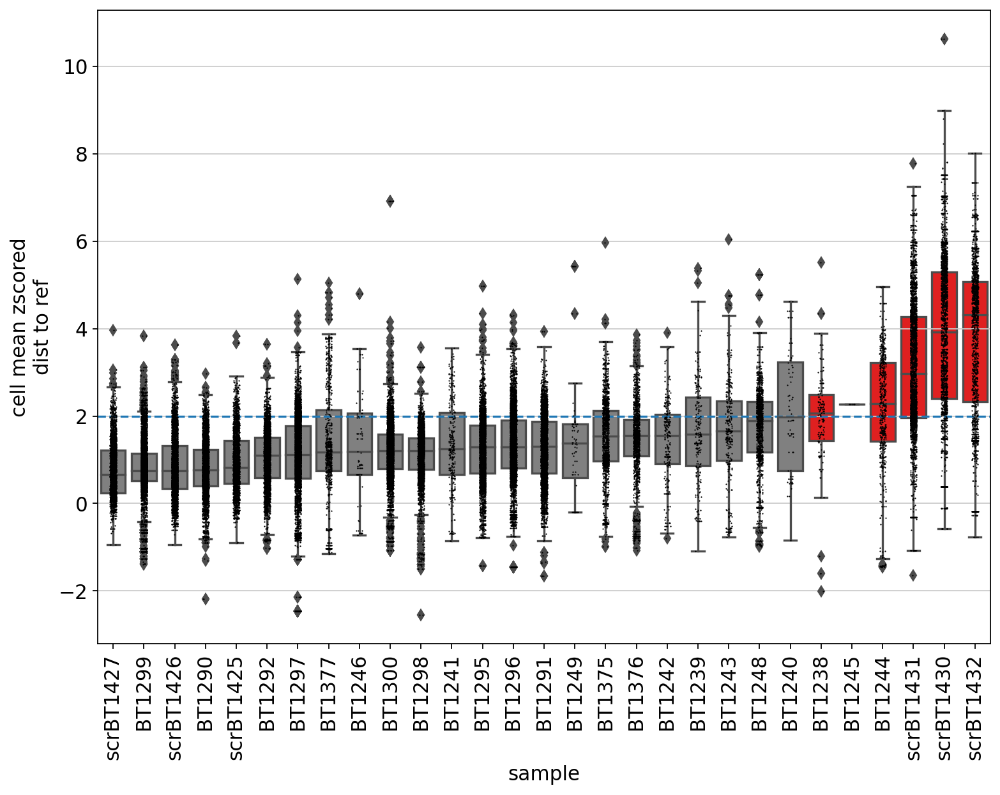

In [27]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease)

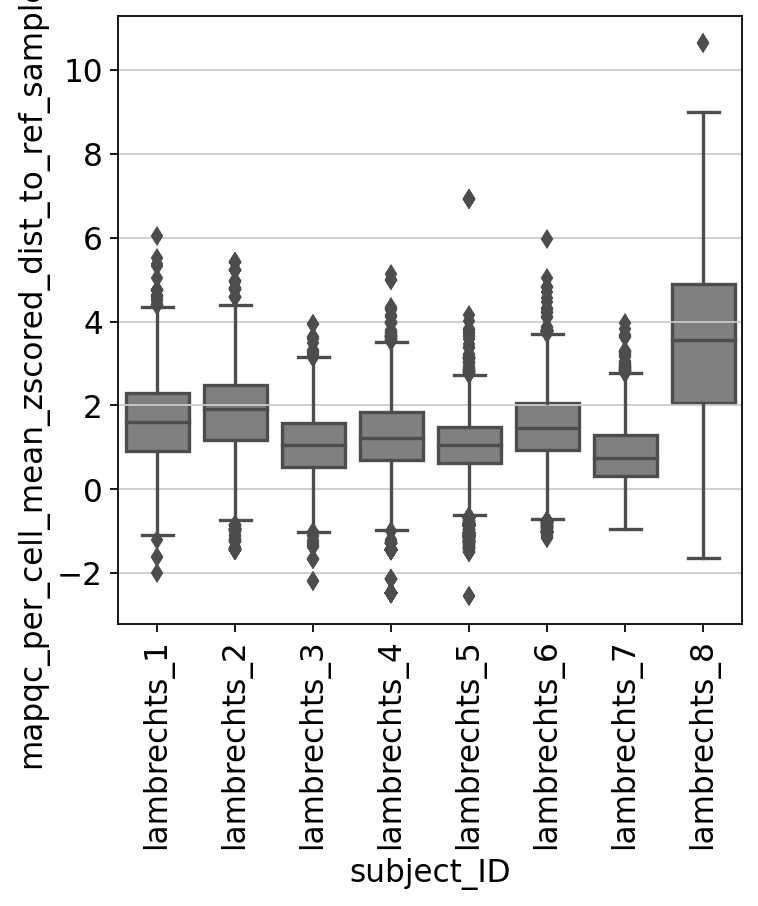

In [52]:
fig, ax = plt.subplots()
sns.boxplot(
    results_disease.adata.obs,
    x="subject_ID",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    color="grey",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)

In [60]:
results_disease.adata.obs.groupby("subject_ID").agg(
    {"sample": "unique", "cancer_type": "first"}
)

,sample,cancer_type
subject_ID,,
lambrechts_1,"['BT1238', 'BT1239', 'BT1240', 'BT1241', 'BT12...",Squamous Cell Carcinoma
lambrechts_2,"['BT1244', 'BT1245', 'BT1246', 'BT1248', 'BT12...",Squamous Cell Carcinoma
lambrechts_3,"['BT1290', 'BT1291', 'BT1292'] Categories (195...",Adenocarcinoma
lambrechts_4,"['BT1295', 'BT1296', 'BT1297'] Categories (195...",Adenocarcinoma
lambrechts_5,"['BT1298', 'BT1299', 'BT1300'] Categories (195...",Large Cell Carcinoma
lambrechts_6,"['BT1375', 'BT1376', 'BT1377'] Categories (195...",Adenocarcinoma
lambrechts_7,"['scrBT1425', 'scrBT1426', 'scrBT1427'] Catego...",Squamous Cell Carcinoma
lambrechts_8,"['scrBT1430', 'scrBT1431', 'scrBT1432'] Catego...",Pleiomorphic Carcinoma


### Analyze non-mixing NK/T cells in healthy:

In [28]:
# palette_ref_q = {
#     "Reference": "lightgrey",
#     "Query control": "dodgerblue",
#     "Query Asherman Syndrome": "darkblue",
# }

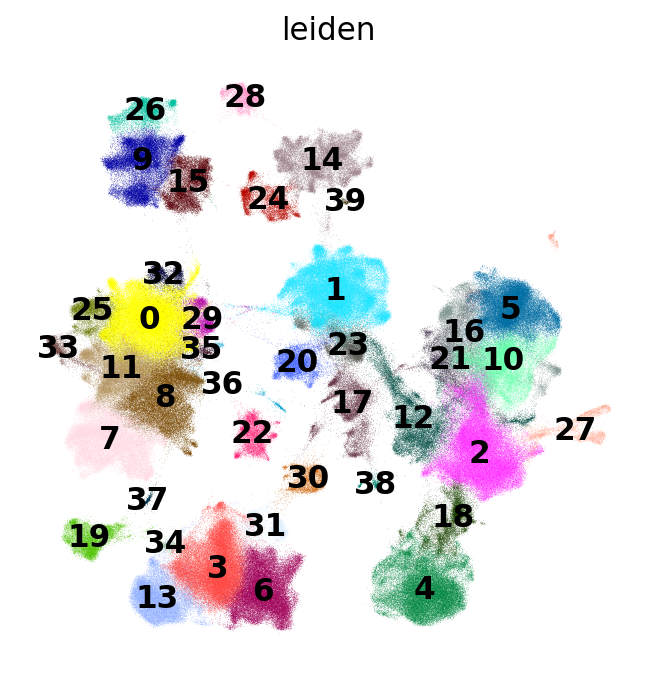

In [29]:
sc.pl.umap(adata_emb, color=["leiden"], frameon=False, legend_loc="on data")

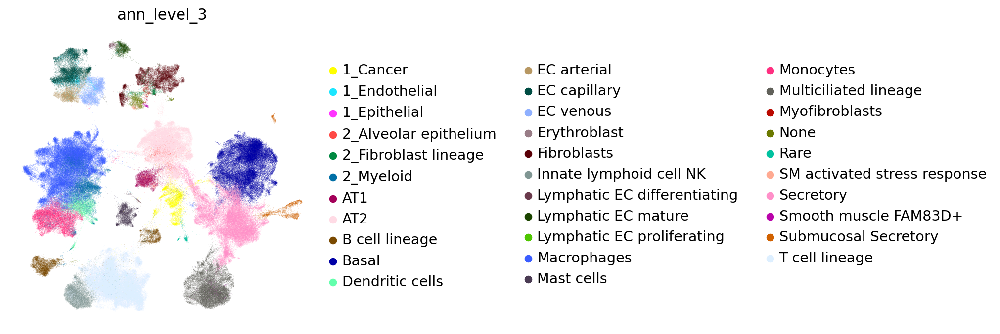

In [30]:
sc.pl.umap(adata_emb, color=["ann_level_3"], frameon=False)

Select based on leiden cluster, but for now use annotations until I have clustering ready:

In [31]:
NK_T_clusters = [3, 6, 13, 31, 34]

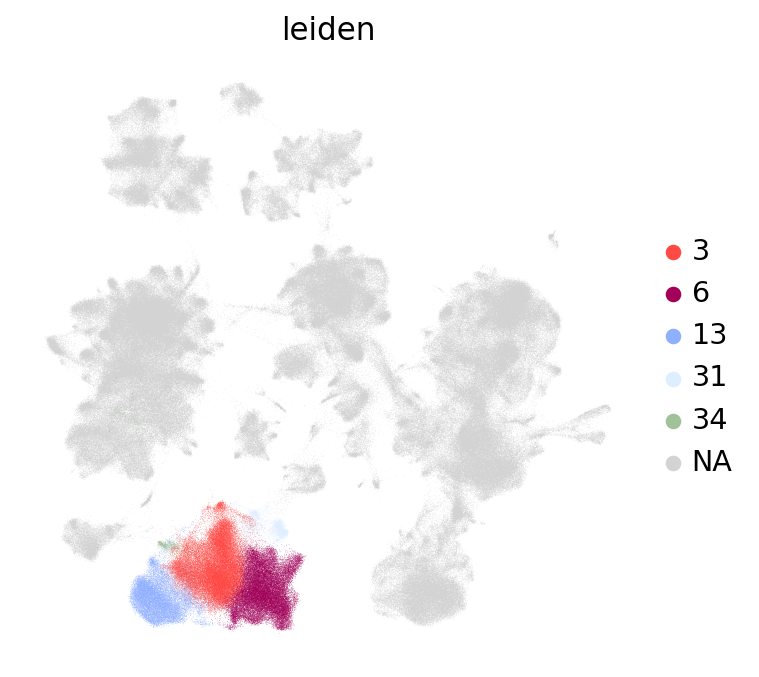

In [32]:
sc.pl.umap(adata_emb, color=["leiden"], frameon=False, groups=NK_T_clusters)

In [33]:
adata_T_ILC_emb = adata_emb[adata_emb.obs.leiden.isin(NK_T_clusters), :].copy()

In [34]:
sc.pp.neighbors(adata_T_ILC_emb, n_neighbors=30)

In [35]:
sc.tl.umap(adata_T_ILC_emb)

In [36]:
sc.tl.leiden(adata_T_ILC_emb, key_added="leiden_T_ILC", resolution=1)

add category specifying sample only for query, or subject only for query:

In [69]:
adata_T_ILC_emb.obs["query_sample"] = np.nan
adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "query_sample"
] = adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "sample"
]
adata_T_ILC_emb.obs["query_subject_ID"] = np.nan
adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "query_subject_ID"
] = adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "subject_ID"
]

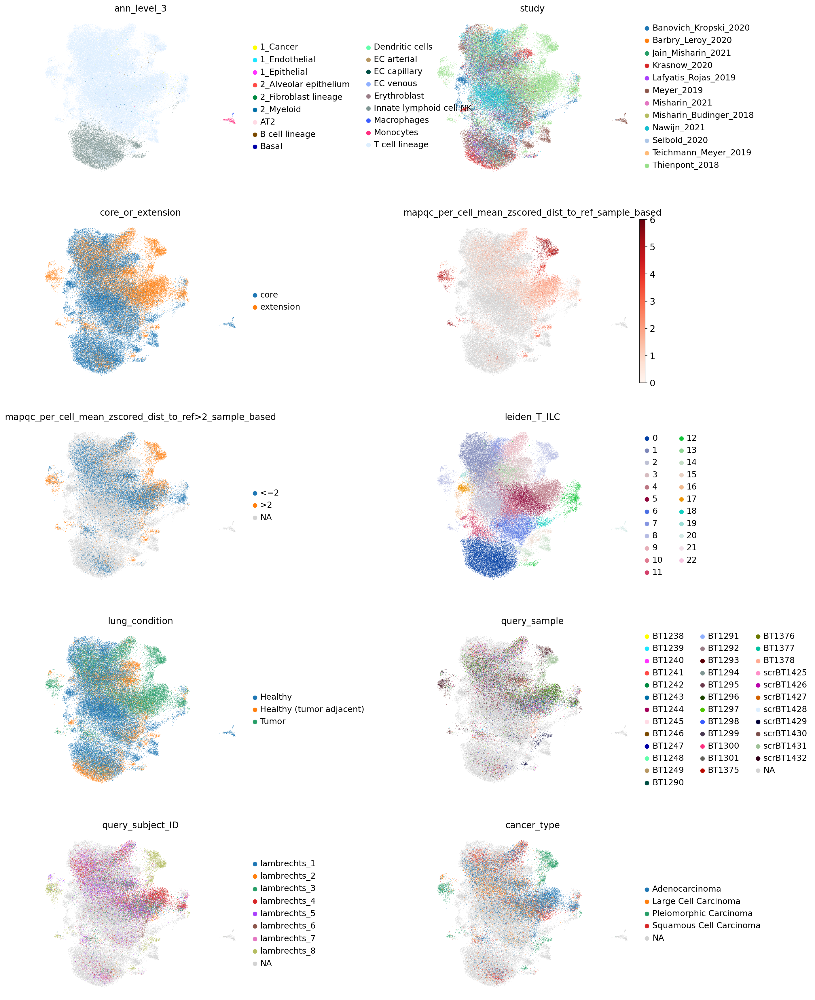

In [70]:
sc.pl.umap(
    adata_T_ILC_emb,
    color=[
        "ann_level_3",
        "study",
        "core_or_extension",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "leiden_T_ILC",
        "lung_condition",
        "query_sample",
        "query_subject_ID",
        "cancer_type",
    ],
    frameon=False,
    ncols=2,
    wspace=0.7,
    cmap="Reds",
    vmin=0,
    vmax=6,
)

#### Include counts

remove lambrechts suffix from adata_full barcodes (this was added for the Thienpont study), so that barcodes of embedding and adata full correspond:

In [39]:
new_idc = [idc.split("_lambrechts")[0] for idc in adata_full.obs.index]
adata_full.obs.index = new_idc

In [40]:
adata_T_ILC = adata_full[adata_T_ILC_emb.obs.index, :].to_memory()

In [68]:
adata_T_ILC.obsm["X_umap"] = adata_T_ILC_emb.obsm["X_umap"]
for obs_cat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "cancer_type",
    "leiden",
    "leiden_T_ILC",
]:
    adata_T_ILC.obs[obs_cat] = adata_T_ILC_emb.obs.loc[adata_T_ILC.obs.index, obs_cat]